# 03 · Regresión con Random Forest

**Responsable:** Lázaro Ruidavets

**Pregunta:** ¿cuántas toneladas va a recibir una estación en un día, por tipo de residuo?

**Datos:** `data/processed/datos_limpios.csv`, generado en `01_preparacion.ipynb`.

Este notebook tiene dos partes:

1. **Exploración de los datos** (Etapa 2): distribución de las toneladas y promedios por mes y por día de la semana.
2. **Modelos** (Etapas 3 y 4): regresión lineal como base y Random Forest, con su evaluación.

In [1]:
# Paso 1 · Librerías

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Paso 2 · Cargar los datos limpios

# parse_dates convierte "fecha" a tipo fecha al leer (en el CSV se guarda como texto)
df = pd.read_csv("../data/processed/datos_limpios.csv", parse_dates=["fecha"])

# Una etiqueta por combinación de estación y tipo de residuo ("Sur · Basura"),
# porque cada combinación tiene otra escala y conviene mirarlas por separado
df["combinacion"] = df["estacion"] + " · " + df["tipo"]

# Orden fijo de las combinaciones y de los días, para que todos los gráficos
# usen el mismo orden y el mismo color para cada combinación
combinaciones = ["Sur · Basura", "Sur · Reciclables", "Sur · Organicos",
                 "Norte · Basura", "Norte · Organicos"]
dias = ["Lunes", "Martes", "Miercoles", "Jueves", "Viernes"]
colores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

print(df.shape)
df.head()

(12408, 12)


,fecha,estacion,tipo,toneladas,viajes,anio,mes,dia_semana,feriado,toneladas_sem_ant,viajes_sem_ant,combinacion
0,2017-01-09,Norte,Basura,99.340123,30,2017,1,Lunes,0,70.523624,23,Norte · Basura
1,2017-01-09,Norte,Organicos,27.591310,7,2017,1,Lunes,0,23.750000,7,Norte · Organicos
2,2017-01-09,Sur,Basura,325.610668,99,2017,1,Lunes,0,364.491521,111,Sur · Basura
3,2017-01-09,Sur,Organicos,211.350862,49,2017,1,Lunes,0,233.762208,48,Sur · Organicos
4,2017-01-09,Sur,Reciclables,402.682309,85,2017,1,Lunes,0,402.273225,93,Sur · Reciclables


In [3]:
# Paso 3 · Resumen de las toneladas por combinación

# Qué hacemos: calcular promedio, mediana, desvío, mínimo y máximo de cada combinación.
# Por qué: antes de graficar conviene tener los números; además muestra cuánto cambia
# la escala entre estaciones, que es lo primero que el modelo tiene que aprender.

# agg aplica varias funciones a la vez; round(1) deja un decimal
resumen = (df.groupby("combinacion")["toneladas"]
             .agg(["count", "mean", "median", "std", "min", "max"])
             .reindex(combinaciones)
             .round(1))
resumen.columns = ["Días", "Promedio", "Mediana", "Desvío", "Mínimo", "Máximo"]
resumen

,Días,Promedio,Mediana,Desvío,Mínimo,Máximo
combinacion,,,,,,
Sur · Basura,2528,364.3,370.0,62.2,0.9,596.7
Sur · Reciclables,2507,312.2,312.2,52.2,0.0,691.0
Sur · Organicos,2512,283.4,283.3,73.1,1.1,566.0
Norte · Basura,2472,88.4,85.8,25.4,6.0,305.5
Norte · Organicos,2389,44.7,31.2,39.7,0.2,245.2


La estación Sur recibe entre 3 y 8 veces más toneladas que la Norte: en promedio, unas 364 toneladas diarias de basura contra 88. Por eso la estación y el tipo de residuo son las primeras variables que el modelo necesita para ubicar el nivel de cada día.

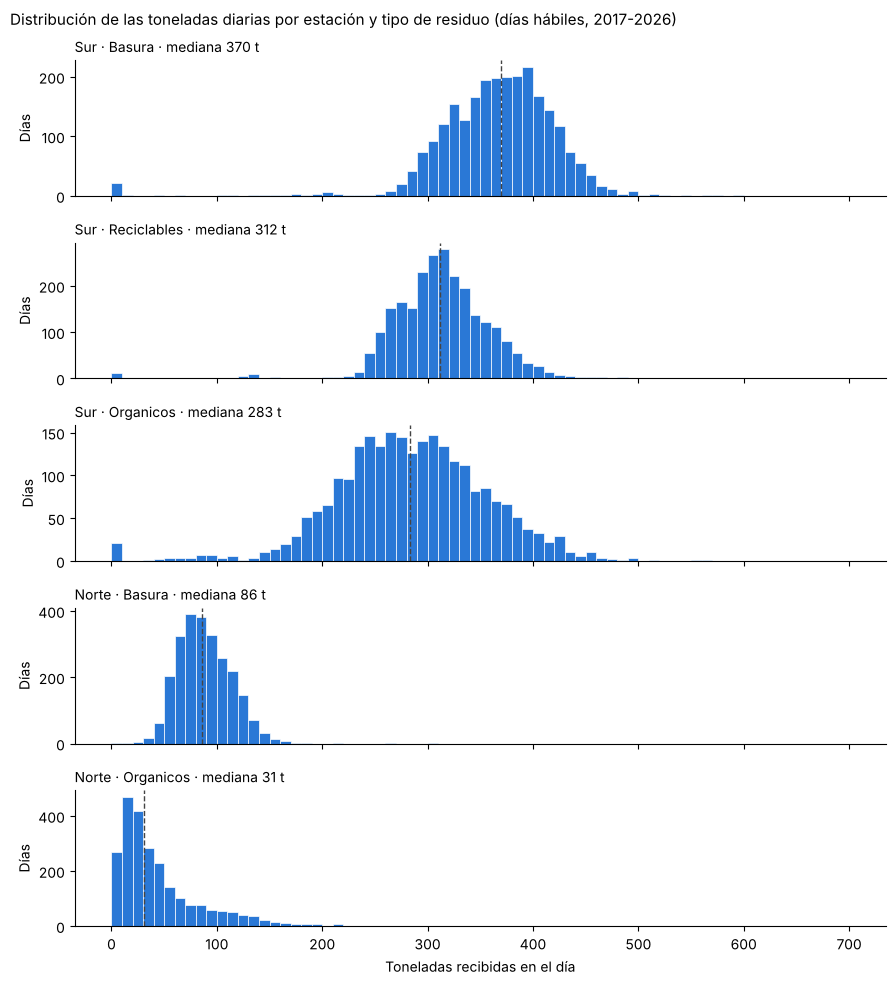

In [4]:
# Paso 4 · Gráfico de distribución de las toneladas

# Qué hacemos: un histograma por combinación, todos con el mismo eje horizontal.
# Por qué: el histograma muestra qué valores son habituales y cuáles son raros.
# Un solo histograma con todo mezclado mostraría varias "montañas" superpuestas
# (una por combinación) y no se entendería; por eso va uno por combinación.

# subplots crea 5 gráficos apilados; sharex=True les da el mismo eje horizontal,
# así se compara directamente dónde está cada combinación
fig, ejes = plt.subplots(5, 1, figsize=(9, 10), sharex=True)

for eje, comb in zip(ejes, combinaciones):
    valores = df.loc[df["combinacion"] == comb, "toneladas"]
    # bins: intervalos de 10 toneladas, de 0 a 700
    eje.hist(valores, bins=range(0, 710, 10), color="#2a78d6", edgecolor="white", linewidth=0.5)
    # Línea vertical en la mediana, para marcar el valor típico
    eje.axvline(valores.median(), color="#444444", linestyle="--", linewidth=1)
    eje.set_title(f"{comb} · mediana {valores.median():.0f} t", loc="left", fontsize=10)
    eje.set_ylabel("Días")
    eje.spines[["top", "right"]].set_visible(False)

ejes[-1].set_xlabel("Toneladas recibidas en el día")
fig.suptitle("Distribución de las toneladas diarias por estación y tipo de residuo (días hábiles, 2017-2026)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

Cada combinación tiene una distribución concentrada alrededor de su propio nivel, y las de la estación Sur están claramente separadas de las de la Norte. Los orgánicos de la Norte son los más dispersos: varían mucho a lo largo del año (se ve en el gráfico por mes). Hay unos pocos días con valores cercanos a cero en la estación Sur, probablemente días con recolección parcial; son muy pocos y se conservan, pero el modelo los va a predecir mal y conviene tenerlo en cuenta al analizar los errores.

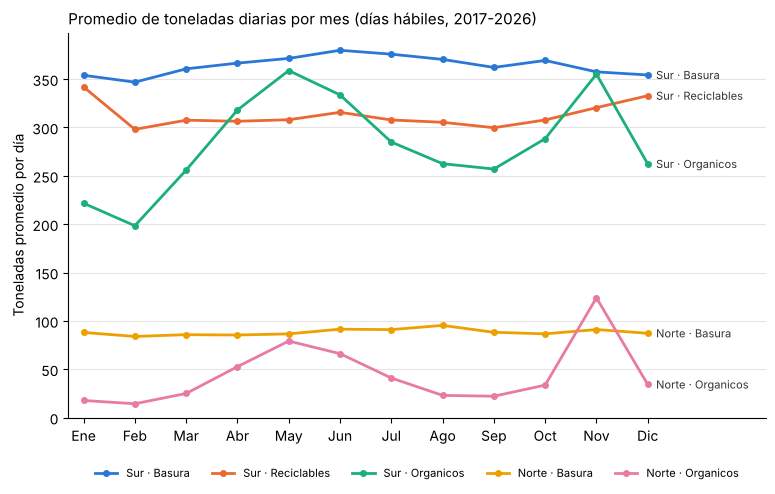

combinacion,Sur · Basura,Sur · Reciclables,Sur · Organicos,Norte · Basura,Norte · Organicos
mes,,,,,
1,354.0,342.0,222.0,88.0,18.0
2,347.0,298.0,198.0,84.0,14.0
3,361.0,307.0,256.0,86.0,25.0
4,367.0,306.0,318.0,85.0,53.0
5,371.0,308.0,359.0,87.0,79.0
6,380.0,316.0,334.0,91.0,66.0
7,376.0,308.0,285.0,91.0,41.0
8,370.0,305.0,263.0,95.0,23.0
9,362.0,300.0,257.0,88.0,22.0


In [5]:
# Paso 5 · Gráfico de promedio de toneladas por mes

# Qué hacemos: el promedio de toneladas de cada mes del año, una línea por combinación.
# Por qué: si hay meses con más o menos residuos (estacionalidad), el mes es una
# variable útil para el modelo. Promediamos todos los años juntos.

# pivot_table arma una tabla: filas = mes, columnas = combinación, valores = promedio
por_mes = df.pivot_table(index="mes", columns="combinacion", values="toneladas", aggfunc="mean")

meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, eje = plt.subplots(figsize=(9, 5))
for comb, color in zip(combinaciones, colores):
    eje.plot(por_mes.index, por_mes[comb], marker="o", markersize=4, linewidth=2, color=color, label=comb)
    # Etiqueta al final de cada línea, para no depender solo del color
    eje.annotate(comb, (12, por_mes.loc[12, comb]), xytext=(6, 0), textcoords="offset points",
                 va="center", fontsize=8, color="#333333")

eje.set_xticks(range(1, 13), meses)
eje.set_xlim(0.7, 14.3)
eje.set_ylim(0, None)
eje.set_ylabel("Toneladas promedio por día")
eje.set_title("Promedio de toneladas diarias por mes (días hábiles, 2017-2026)", loc="left", fontsize=11)
eje.grid(axis="y", color="#e5e5e5")
eje.spines[["top", "right"]].set_visible(False)
eje.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=5)
plt.show()

# La tabla con los mismos valores, redondeados
por_mes[combinaciones].round(0)

Los orgánicos son el único residuo con una estacionalidad marcada: suben en primavera (mayo) y tienen su pico en noviembre, que coincide con la caída de hojas, mientras que enero y febrero son los meses más bajos. En la Norte, los orgánicos pasan de unas 14 toneladas en febrero a 124 en noviembre. La basura y los reciclables se mantienen casi constantes durante el año, con una leve suba de reciclables en diciembre y enero (fiestas). Por eso el mes es una variable útil, sobre todo combinada con el tipo de residuo: un efecto que un árbol puede captar y una regresión lineal simple no.

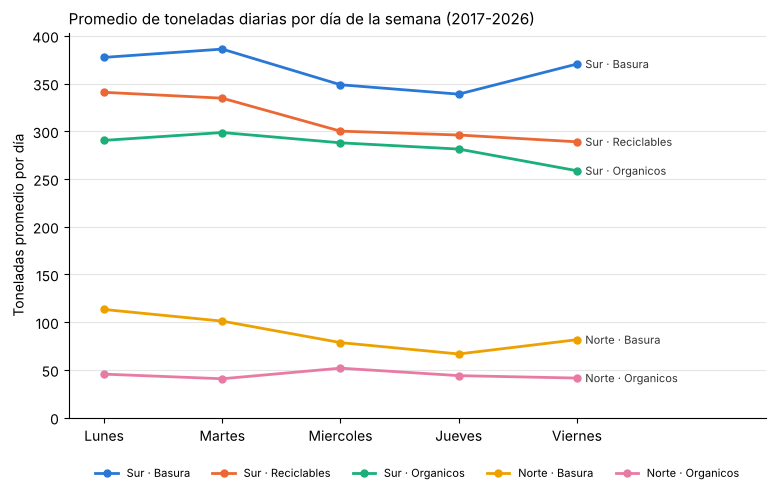

combinacion,Sur · Basura,Sur · Reciclables,Sur · Organicos,Norte · Basura,Norte · Organicos
dia_semana,,,,,
Lunes,377.0,341.0,290.0,113.0,46.0
Martes,386.0,335.0,299.0,101.0,41.0
Miercoles,349.0,300.0,288.0,79.0,52.0
Jueves,339.0,296.0,281.0,67.0,44.0
Viernes,370.0,289.0,259.0,82.0,41.0


In [6]:
# Paso 6 · Gráfico de promedio de toneladas por día de la semana

# Qué hacemos: el promedio de toneladas de cada día hábil, una línea por combinación.
# Por qué: si la carga cambia según el día, el día de la semana es una variable útil.

por_dia = df.pivot_table(index="dia_semana", columns="combinacion", values="toneladas", aggfunc="mean")
# reindex ordena los días de lunes a viernes (si no, quedarían en orden alfabético)
por_dia = por_dia.reindex(dias)

fig, eje = plt.subplots(figsize=(9, 5))
for comb, color in zip(combinaciones, colores):
    eje.plot(dias, por_dia[comb], marker="o", markersize=5, linewidth=2, color=color, label=comb)
    eje.annotate(comb, (4, por_dia.loc["Viernes", comb]), xytext=(6, 0), textcoords="offset points",
                 va="center", fontsize=8, color="#333333")

eje.set_xlim(-0.3, 5.6)
eje.set_ylim(0, None)
eje.set_ylabel("Toneladas promedio por día")
eje.set_title("Promedio de toneladas diarias por día de la semana (2017-2026)", loc="left", fontsize=11)
eje.grid(axis="y", color="#e5e5e5")
eje.spines[["top", "right"]].set_visible(False)
eje.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=5)
plt.show()

por_dia[combinaciones].round(0)

La carga es más alta al comienzo de la semana: lunes y martes son los días más fuertes en casi todas las combinaciones, y el jueves suele ser el más bajo. Es probable que el lunes acumule parte de lo que no se recolecta el fin de semana. La basura de las dos estaciones vuelve a subir el viernes, mientras que los reciclables y los orgánicos de la Sur siguen bajando. Como el patrón cambia según la combinación, el día de la semana conviene usarlo junto con la estación y el tipo de residuo.

In [7]:
# Paso 7 · Efecto de los feriados

# Qué hacemos: comparar el promedio de toneladas en feriados y en días comunes.
# Por qué: si un feriado cambia la carga, la variable "feriado" le sirve al modelo.

feriados = (df.pivot_table(index="combinacion", columns="feriado", values="toneladas", aggfunc="mean")
              .reindex(combinaciones).round(0))
feriados.columns = ["Día común", "Feriado"]
print("Días feriados en el dataset:", df["feriado"].sum())
feriados

Días feriados en el dataset: 425


,Día común,Feriado
combinacion,,
Sur · Basura,368.0,285.0
Sur · Reciclables,313.0,282.0
Sur · Organicos,286.0,230.0
Norte · Basura,88.0,101.0
Norte · Organicos,45.0,46.0


Hay 425 filas de días hábiles feriados. En la estación Sur, los feriados reciben entre 30 y 80 toneladas menos que un día común; en la Norte la diferencia es chica. El efecto existe, pero hay pocos casos, así que el modelo lo va a aprender con menos precisión que el del día o el mes.

---
# Parte 2 · Modelos de regresión

Se entrenan dos modelos con las mismas entradas y la misma división temporal:

- **Regresión lineal**, como base de comparación.
- **Random Forest**, el modelo principal.

Cada uno se entrena **con y sin** las variables de la semana anterior, para medir cuánto aportan.

In [8]:
# Paso 8 · Librerías de los modelos

# LinearRegression: regresión lineal por mínimos cuadrados (la base de comparación)
from sklearn.linear_model import LinearRegression
# RandomForestRegressor: el bosque de árboles de regresión
from sklearn.ensemble import RandomForestRegressor
# mean_absolute_error calcula el MAE: el promedio de |real - predicho|, en toneladas
from sklearn.metrics import mean_absolute_error

# Semilla fija: el Random Forest usa azar (muestras y variables por división).
# Con la misma semilla, cada ejecución da exactamente los mismos resultados
SEMILLA = 42

In [9]:
# Paso 9 · Variables de entrada

# Qué hacemos: definir qué columnas puede usar el modelo para predecir.
# Por qué: es acá donde se aplica la regla contra la fuga de información.

# Lista explícita de entradas permitidas (las mismas que usa el notebook 02).
# NO está 'viajes' del mismo día: tiene correlación de 0,95 con las toneladas
# y se conoce recién cuando el día terminó. Usarla sería darle la respuesta al modelo.
entradas_calendario = ["estacion", "tipo", "dia_semana", "anio", "mes", "feriado"]
entradas_sem_ant = ["toneladas_sem_ant", "viajes_sem_ant"]  # ya ocurrieron: son válidas

# Dos versiones de las entradas: con y sin la semana anterior
versiones = {
    "Sin semana anterior": entradas_calendario,
    "Con semana anterior": entradas_calendario + entradas_sem_ant,
}

# La variable objetivo
y = df["toneladas"]

In [10]:
# Paso 10 · Codificación one-hot

# Qué hacemos: transformar estación, tipo y día de la semana en columnas de 0 y 1.
# Por qué: scikit-learn solo trabaja con números, y asignar Norte = 1 y Sur = 2
# haría creer al modelo que existe un orden. Es la misma codificación del notebook 02.

# Un diccionario con una tabla X por cada versión de las entradas
X = {
    nombre: pd.get_dummies(df[columnas], columns=["estacion", "tipo", "dia_semana"], dtype=int)
    for nombre, columnas in versiones.items()
}

print(X["Con semana anterior"].columns.tolist())

['anio', 'mes', 'feriado', 'toneladas_sem_ant', 'viajes_sem_ant', 'estacion_Norte', 'estacion_Sur', 'tipo_Basura', 'tipo_Organicos', 'tipo_Reciclables', 'dia_semana_Jueves', 'dia_semana_Lunes', 'dia_semana_Martes', 'dia_semana_Miercoles', 'dia_semana_Viernes']


In [11]:
# Paso 11 · División en entrenamiento y prueba

# Qué hacemos: separar los datos por fecha, con el corte acordado (1/12/2024).
# Por qué: el modelo tiene que predecir días futuros. Si se mezclaran al azar,
# entrenaría con días posteriores a los que predice y el error parecería menor que el real.

CORTE = pd.Timestamp("2024-12-01")

# Máscaras de True/False: cada fila va a entrenamiento o a prueba según su fecha
es_entrenamiento = df["fecha"] < CORTE
es_prueba = df["fecha"] >= CORTE

print("Entrenamiento:", es_entrenamiento.sum(), "filas,",
      df.loc[es_entrenamiento, "fecha"].min().date(), "a", df.loc[es_entrenamiento, "fecha"].max().date())
print("Prueba:       ", es_prueba.sum(), "filas,",
      df.loc[es_prueba, "fecha"].min().date(), "a", df.loc[es_prueba, "fecha"].max().date())
print(f"Proporción de prueba: {es_prueba.mean():.1%}")

Entrenamiento: 10072 filas, 2017-01-09 a 2024-11-29
Prueba:        2336 filas, 2024-12-02 a 2026-09-28
Proporción de prueba: 18.8%


El entrenamiento va del 9/01/2017 al 29/11/2024 (10.072 filas) y la prueba del 2/12/2024 al 28/09/2026 (2.336 filas, 18,8 %). Todo lo que el modelo predice en prueba es posterior a lo que vio al entrenar.

In [12]:
# Paso 12 · Bases triviales

# Qué hacemos: calcular el error de dos predicciones que no necesitan ningún modelo.
# Por qué: un modelo solo vale la pena si se equivoca menos que estas reglas simples.

y_prueba = y[es_prueba]

# Regla 1: "hoy va a ser igual al mismo día de la semana anterior"
mae_semana_anterior = mean_absolute_error(y_prueba, df.loc[es_prueba, "toneladas_sem_ant"])

# Regla 2: "hoy va a ser el promedio histórico de esta estación y tipo"
# (el promedio se calcula solo con entrenamiento, para no usar datos de prueba)
promedios = df[es_entrenamiento].groupby(["estacion", "tipo"])["toneladas"].mean()
pred_promedio = df[es_prueba].set_index(["estacion", "tipo"]).index.map(promedios)
mae_promedio = mean_absolute_error(y_prueba, pred_promedio)

print(f"MAE · mismo día de la semana anterior: {mae_semana_anterior:.1f} t")
print(f"MAE · promedio de la estación y tipo:  {mae_promedio:.1f} t")
print(f"Toneladas promedio por día en prueba:   {y_prueba.mean():.1f} t")

MAE · mismo día de la semana anterior: 27.1 t
MAE · promedio de la estación y tipo:  44.8 t
Toneladas promedio por día en prueba:   212.0 t


Repetir el valor de la semana anterior ya da un error de 27,1 toneladas, un 12,8 % de las 212 toneladas de un día promedio de prueba. Es la vara que tiene que superar un modelo: si no le gana a esta regla, no aporta nada. Usar el promedio de cada estación y tipo es mucho peor (44,8 t), porque ignora el día, el mes y los feriados.

In [13]:
# Paso 13 · Regresión lineal (base de comparación)

# Qué hacemos: entrenar la regresión lineal con cada versión de las entradas y medir su MAE.
# Por qué: es el modelo más simple que aprende de los datos. El Random Forest
# tiene que mejorarla para justificar su complejidad.

resultados = {}   # acá guardamos el MAE de cada modelo
predicciones = {} # y sus predicciones sobre prueba

for nombre in versiones:
    # PREPARACIÓN: entradas de entrenamiento y de prueba de esta versión
    X_ent, X_pru = X[nombre][es_entrenamiento], X[nombre][es_prueba]

    # ENTRENAMIENTO: fit busca los coeficientes que minimizan el error cuadrático
    lineal = LinearRegression()
    lineal.fit(X_ent, y[es_entrenamiento])

    # PREDICCIÓN: toneladas estimadas para los días de prueba
    pred = lineal.predict(X_pru)
    predicciones[("Regresión lineal", nombre)] = pred
    resultados[("Regresión lineal", nombre)] = mean_absolute_error(y_prueba, pred)
    print(f"Regresión lineal · {nombre}: MAE = {resultados[('Regresión lineal', nombre)]:.1f} t")

Regresión lineal · Sin semana anterior: MAE = 45.8 t
Regresión lineal · Con semana anterior: MAE = 29.5 t


Sin la semana anterior, la regresión lineal (45,8 t) prácticamente no mejora al promedio por estación y tipo. Solo puede sumar efectos fijos: no capta que el mes afecte distinto a cada tipo de residuo, y trata el mes como un número (diciembre = 12), como si la carga creciera de enero a diciembre. Con la semana anterior baja a 29,5 t, pero sigue sin superar la regla trivial de repetir la semana anterior.

In [14]:
# Paso 14 · Elegir los parámetros del Random Forest

# Qué hacemos: probar algunas combinaciones de profundidad máxima y mínimo de casos por hoja.
# Por qué: un árbol muy profundo memoriza el entrenamiento (sobreajuste); uno muy corto
# no capta los patrones. Para elegir NO se usa el conjunto de prueba, porque entonces
# el error de prueba dejaría de ser una medida honesta. Se separa el último año del
# entrenamiento (dic-2023 a nov-2024) como "validación" y se elige con ese año.

X_val_base = X["Con semana anterior"]
es_sub_ent = df["fecha"] < "2023-12-01"
es_validacion = es_entrenamiento & ~es_sub_ent

filas = []
for profundidad in [5, 10, 15, None]:      # None = sin límite de profundidad
    for min_hoja in [1, 5, 20]:
        modelo = RandomForestRegressor(n_estimators=200, max_depth=profundidad,
                                       min_samples_leaf=min_hoja, random_state=SEMILLA, n_jobs=-1)
        modelo.fit(X_val_base[es_sub_ent], y[es_sub_ent])
        error = mean_absolute_error(y[es_validacion], modelo.predict(X_val_base[es_validacion]))
        filas.append({"max_depth": profundidad, "min_samples_leaf": min_hoja, "MAE validación (t)": round(error, 1)})

busqueda = pd.DataFrame(filas)
# Tabla: filas = profundidad, columnas = mínimo por hoja
busqueda.pivot(index="max_depth", columns="min_samples_leaf", values="MAE validación (t)")

min_samples_leaf,1,5,20
max_depth,,,
NaN,23.0,21.6,22.3
5.0,23.9,23.8,23.5
10.0,22.2,21.5,22.3
15.0,22.8,21.6,22.3


La combinación con menor error de validación es profundidad 10 con al menos 5 días por hoja (21,5 t). Las diferencias entre combinaciones son chicas (de 21,5 a 23,9 t), así que el modelo no es muy sensible a estos parámetros. Con 1 caso por hoja el error sube: el árbol aprende días sueltos que no se repiten (sobreajuste). Con profundidad 5, los árboles quedan demasiado simples.

In [15]:
# Paso 15 · Random Forest

# Parámetros elegidos (según la validación del paso anterior):
# - n_estimators=300: cantidad de árboles. Desde unos 100 el error ya no cambia;
#   300 da un promedio estable y entrena en pocos segundos.
# - max_depth=10: cada árbol hace como máximo 10 preguntas seguidas. Tuvo el menor
#   error de validación; árboles más profundos no mejoraron.
# - min_samples_leaf=5: cada hoja promedia al menos 5 días, así no aprende de un día suelto.
PARAMETROS_RF = dict(n_estimators=300, max_depth=10, min_samples_leaf=5,
                     random_state=SEMILLA, n_jobs=-1)

bosques = {}
for nombre in versiones:
    # PREPARACIÓN
    X_ent, X_pru = X[nombre][es_entrenamiento], X[nombre][es_prueba]

    # ENTRENAMIENTO: cada árbol se entrena con una muestra al azar de los días
    bosque = RandomForestRegressor(**PARAMETROS_RF)
    bosque.fit(X_ent, y[es_entrenamiento])
    bosques[nombre] = bosque

    # PREDICCIÓN: el promedio de los 300 árboles para cada día de prueba
    pred = bosque.predict(X_pru)
    predicciones[("Random Forest", nombre)] = pred
    resultados[("Random Forest", nombre)] = mean_absolute_error(y_prueba, pred)

    # MAE en entrenamiento, para ver si hay sobreajuste (si es mucho menor que en prueba)
    mae_ent = mean_absolute_error(y[es_entrenamiento], bosque.predict(X_ent))
    print(f"Random Forest · {nombre}: MAE prueba = {resultados[('Random Forest', nombre)]:.1f} t"
          f" · MAE entrenamiento = {mae_ent:.1f} t")

Random Forest · Sin semana anterior: MAE prueba = 25.2 t · MAE entrenamiento = 18.7 t
Random Forest · Con semana anterior: MAE prueba = 25.2 t · MAE entrenamiento = 18.3 t


El Random Forest se equivoca en promedio 25,2 toneladas por día en las dos versiones. El error en entrenamiento (18,3 a 18,7 t) es menor, como es esperable, pero la diferencia es moderada: no hay un sobreajuste fuerte.

Un resultado importante: **la semana anterior no mejora al Random Forest**. Con estación, tipo, día, mes y feriado el bosque ya aprende el nivel esperado de cada día, que es justamente lo que aporta la semana anterior. A la regresión lineal, en cambio, sí la ayuda mucho, porque le da un nivel que ella sola no logra construir.

In [16]:
# Paso 16 · Comparación de todos los modelos

# Qué hacemos: juntar en una tabla el MAE de las bases triviales y de los modelos.
# Por qué: es la respuesta a "¿cuánto se equivoca y cuál conviene?".

tabla = pd.DataFrame([
    {"Modelo": "Mismo día de la semana anterior", "Entradas": "—", "MAE (t)": mae_semana_anterior},
    {"Modelo": "Promedio de estación y tipo", "Entradas": "—", "MAE (t)": mae_promedio},
] + [
    {"Modelo": modelo, "Entradas": entradas, "MAE (t)": error}
    for (modelo, entradas), error in resultados.items()
])
# Error relativo: el MAE como porcentaje de las toneladas promedio de un día de prueba
tabla["% del promedio diario"] = (tabla["MAE (t)"] / y_prueba.mean() * 100).round(1)
tabla["MAE (t)"] = tabla["MAE (t)"].round(1)
tabla.sort_values("MAE (t)")

,Modelo,Entradas,MAE (t),% del promedio diario
5,Random Forest,Con semana anterior,25.2,11.9
4,Random Forest,Sin semana anterior,25.2,11.9
0,Mismo día de la semana anterior,—,27.1,12.8
3,Regresión lineal,Con semana anterior,29.5,13.9
1,Promedio de estación y tipo,—,44.8,21.2
2,Regresión lineal,Sin semana anterior,45.8,21.6


El Random Forest es el mejor modelo, con un error del 11,9 % de un día promedio. Mejora a la regresión lineal en 4,3 toneladas y a la regla de la semana anterior en unas 2 toneladas. La ganancia frente a la regla trivial es modesta, y conviene decirlo así en el informe: la carga diaria es bastante regular y gran parte del error viene de días atípicos (ver el Paso 21).

In [17]:
# Paso 17 · Ejemplos de valores reales y predichos

# Qué hacemos: mostrar algunos días de prueba con lo que pasó y lo que predijo cada modelo.
# Por qué: la consigna lo pide, y un ejemplo concreto se entiende mejor que un promedio.

ejemplos = df.loc[es_prueba, ["fecha", "estacion", "tipo", "dia_semana", "toneladas"]].copy()
ejemplos["Lineal"] = predicciones[("Regresión lineal", "Con semana anterior")]
ejemplos["Random Forest"] = predicciones[("Random Forest", "Con semana anterior")]
ejemplos["Error RF"] = ejemplos["Random Forest"] - ejemplos["toneladas"]

# Un ejemplo por combinación en una misma fecha (aciertos y errores típicos),
# más los 3 días con mayor error del Random Forest
fecha_ejemplo = pd.Timestamp("2025-03-11")
tipicos = ejemplos[ejemplos["fecha"] == fecha_ejemplo]
peores = ejemplos.reindex(ejemplos["Error RF"].abs().sort_values(ascending=False).index).head(3)

pd.concat([tipicos, peores]).round({"toneladas": 1, "Lineal": 1, "Random Forest": 1, "Error RF": 1})

,fecha,estacion,tipo,dia_semana,toneladas,Lineal,Random Forest,Error RF
10403,2025-03-11,Norte,Basura,Martes,88.2,106.4,100.4,12.2
10404,2025-03-11,Norte,Organicos,Martes,12.8,34.3,23.2,10.3
10405,2025-03-11,Sur,Basura,Martes,430.5,402.5,417.3,-13.1
10406,2025-03-11,Sur,Organicos,Martes,237.6,307.8,302.6,65.0
10407,2025-03-11,Sur,Reciclables,Martes,294.9,300.9,310.1,15.2
12406,2026-09-28,Sur,Organicos,Lunes,1.5,232.5,363.3,361.8
10293,2025-02-05,Sur,Basura,Miercoles,16.2,340.0,361.7,345.5
12405,2026-09-28,Sur,Basura,Lunes,7.8,313.0,332.2,324.4


En un martes común (11/03/2025) el bosque se equivoca entre 10 y 15 toneladas en casi todas las combinaciones; el mayor desvío es en orgánicos de la Sur (65 t). Los peores errores son días en que casi no se recibió nada, como el 5/02/2025 (nevada en Seattle) o el 28/09/2026, último día del archivo: el modelo predice un día normal y la realidad es casi cero.

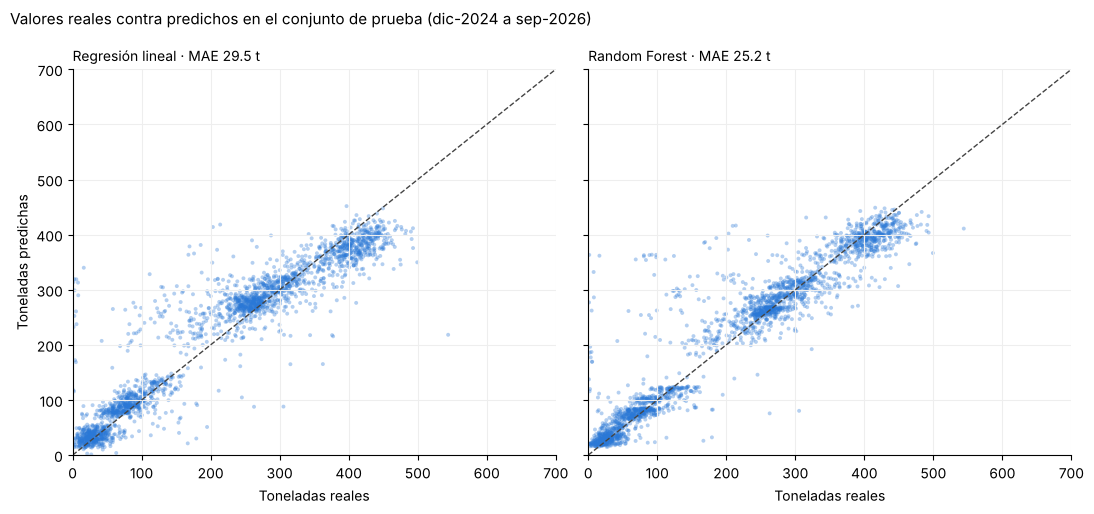

In [18]:
# Paso 18 · Gráfico de valores reales contra predichos

# Qué hacemos: un punto por día de prueba: real en el eje horizontal, predicho en el vertical.
# Por qué: si el modelo fuera perfecto, todos los puntos caerían sobre la diagonal.
# Lo lejos que quedan de ella muestra el tamaño y la dirección de los errores.

fig, ejes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True, sharey=True)
for eje, modelo in zip(ejes, ["Regresión lineal", "Random Forest"]):
    pred = predicciones[(modelo, "Con semana anterior")]
    eje.scatter(y_prueba, pred, s=8, alpha=0.35, color="#2a78d6", edgecolors="none")
    # Diagonal: predicción perfecta
    eje.plot([0, 700], [0, 700], color="#444444", linestyle="--", linewidth=1)
    eje.set_title(f"{modelo} · MAE {resultados[(modelo, 'Con semana anterior')]:.1f} t", loc="left", fontsize=10)
    eje.set_xlabel("Toneladas reales")
    eje.set_xlim(0, 700); eje.set_ylim(0, 700)
    eje.grid(color="#eeeeee")
    eje.spines[["top", "right"]].set_visible(False)
ejes[0].set_ylabel("Toneladas predichas")
fig.suptitle("Valores reales contra predichos en el conjunto de prueba (dic-2024 a sep-2026)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

La mayoría de los puntos del Random Forest se agrupan cerca de la diagonal, en nubes que corresponden a los distintos niveles de cada estación y tipo. Los puntos de abajo a la derecha son días con un valor real casi nulo que el modelo predijo como normales: feriados sin recolección, nevadas y los datos incompletos de septiembre de 2026. La regresión lineal tiene nubes más anchas.

Sin semana anterior {'Estación': 0.872, 'Tipo de residuo': 0.041, 'Mes': 0.039, 'Año': 0.024, 'Día de la semana': 0.017, 'Feriado': 0.006}
Con semana anterior {'Estación': 0.866, 'Toneladas semana anterior': 0.093, 'Viajes semana anterior': 0.013, 'Mes': 0.011, 'Día de la semana': 0.005, 'Feriado': 0.005, 'Año': 0.004, 'Tipo de residuo': 0.004}


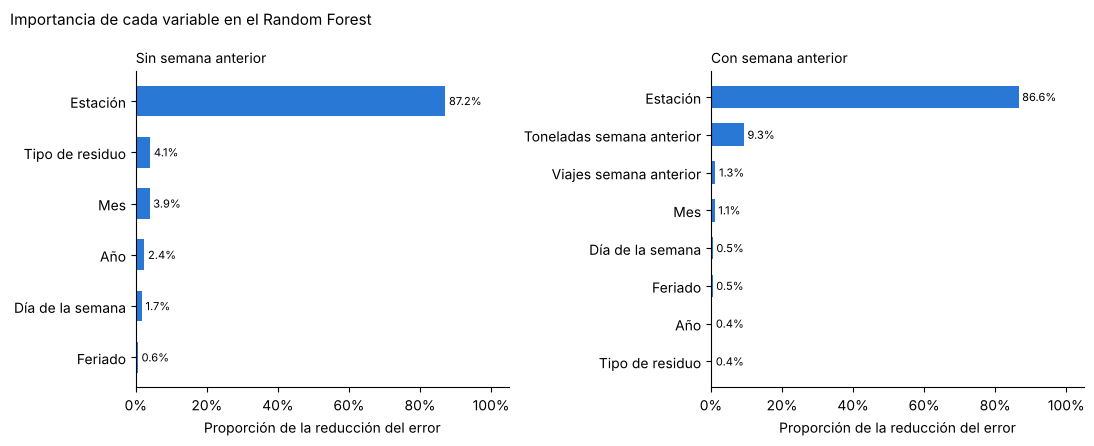

In [19]:
# Paso 19 · Importancia de las variables

# Qué hacemos: ver cuánto contribuyó cada variable a reducir el error en el bosque.
# Por qué: permite explicar en qué se basa el modelo.

# La codificación one-hot partió cada variable categórica en varias columnas
# (estacion_Norte y estacion_Sur son la misma información). Para leer la importancia
# por variable, sumamos las columnas que salieron de la misma variable original.
def variable_original(columna):
    for prefijo in ["estacion", "tipo", "dia_semana"]:
        if columna.startswith(prefijo + "_"):
            return prefijo
    return columna

nombres_legibles = {"estacion": "Estación", "tipo": "Tipo de residuo", "dia_semana": "Día de la semana",
                    "anio": "Año", "mes": "Mes", "feriado": "Feriado",
                    "toneladas_sem_ant": "Toneladas semana anterior", "viajes_sem_ant": "Viajes semana anterior"}

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for eje, nombre in zip(ejes, versiones):
    importancia = pd.Series(bosques[nombre].feature_importances_, index=X[nombre].columns)
    importancia = importancia.groupby(variable_original).sum().sort_values()
    importancia.index = importancia.index.map(nombres_legibles)
    eje.barh(importancia.index, importancia.values, color="#2a78d6", height=0.6)
    for i, v in enumerate(importancia.values):
        eje.text(v + 0.01, i, f"{v:.1%}", va="center", fontsize=8)
    eje.set_title(nombre, loc="left", fontsize=10)
    eje.set_xlim(0, 1.05)
    eje.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    eje.set_xlabel("Proporción de la reducción del error")
    eje.spines[["top", "right"]].set_visible(False)
    print(nombre, importancia.sort_values(ascending=False).round(3).to_dict())
fig.suptitle("Importancia de cada variable en el Random Forest", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

La estación explica el 87 % de la reducción del error en las dos versiones: separar la Norte de la Sur es lo primero que hace el bosque, porque la Sur recibe entre 3 y 8 veces más. Sin la semana anterior, el resto se reparte entre el tipo de residuo (4,1 %), el mes (3,9 %), el año (2,4 %) y el día (1,7 %). Con la semana anterior, las toneladas de esa semana toman un 9,3 % y el tipo, el mes y el día casi desaparecen: el dato de la semana anterior ya trae incorporados el tipo de residuo y la época del año. Por eso las dos versiones terminan con el mismo error. El año pesa poco (2,4 % o menos), así que la limitación del Random Forest para extrapolar años nuevos casi no afecta a este caso, donde el total anual se mantiene estable.

In [20]:
# Paso 20 · ¿Dónde se equivoca más?

# Qué hacemos: calcular el MAE del Random Forest por combinación, por día y en feriados.
# Por qué: un promedio general puede esconder que el modelo anda bien en unos casos y mal en otros.

errores = df.loc[es_prueba, ["estacion", "tipo", "combinacion", "dia_semana", "feriado", "toneladas"]].copy()
errores["error_abs"] = (predicciones[("Random Forest", "Con semana anterior")] - errores["toneladas"]).abs()

def resumen_error(columna, orden=None):
    t = errores.groupby(columna).agg(dias=("error_abs", "size"),
                                     MAE=("error_abs", "mean"),
                                     promedio_real=("toneladas", "mean"))
    t["% del promedio"] = t["MAE"] / t["promedio_real"] * 100
    if orden is not None:
        t = t.reindex(orden)
    return t.round(1)

print("Por estación y tipo de residuo")
display(resumen_error("combinacion", combinaciones))
print("Por día de la semana")
display(resumen_error("dia_semana", dias))
print("Feriado (0 = no, 1 = sí)")
display(resumen_error("feriado"))

Por estación y tipo de residuo


,dias,MAE,promedio_real,% del promedio
combinacion,,,,
Sur · Basura,476,34.1,395.1,8.6
Sur · Reciclables,467,21.9,275.8,8.0
Sur · Organicos,474,39.9,254.3,15.7
Norte · Basura,463,15.4,87.8,17.5
Norte · Organicos,456,14.1,37.6,37.6


Por día de la semana


,dias,MAE,promedio_real,% del promedio
dia_semana,,,,
Lunes,476,26.3,227.9,11.5
Martes,475,24.1,222.1,10.9
Miercoles,460,26.1,207.8,12.6
Jueves,456,26.2,199.8,13.1
Viernes,469,23.5,201.6,11.7


Feriado (0 = no, 1 = sí)


,dias,MAE,promedio_real,% del promedio
feriado,,,,
0,2259,24.0,213.1,11.3
1,77,62.1,179.4,34.6


En toneladas, el mayor error está en los orgánicos de la Sur (39,9 t), el tipo de residuo con más estacionalidad. En proporción, los más difíciles son los orgánicos de la Norte: 14 t de error sobre 38 t de promedio (37,6 %), porque son volúmenes chicos y muy variables. El día de la semana casi no cambia el error (de 23,5 a 26,3 t). En feriados, en cambio, el error se multiplica por 2,6: 62,1 t contra 24,0 t de un día común.

In [21]:
# Paso 21 · Días atípicos que inflan el error

# Qué hacemos: revisar dos grupos de días donde el modelo falla mucho.
# Por qué: al mirar los mayores errores aparecieron dos patrones que no son culpa
# del modelo sino de los datos, y conviene medir cuánto pesan.

# 1) Desde el 7/09/2026, la estación Sur registra cerca de la mitad de lo habitual
#    en los tres tipos de residuo, mientras la Norte sigue igual. El 28/09 casi no hay datos.
total_diario = df.groupby("fecha")["toneladas"].sum()
print("Total diario promedio, ago-2026:", round(total_diario["2026-08-01":"2026-09-04"].mean()), "t")
print("Total diario promedio, 7 al 25/09/2026:", round(total_diario["2026-09-07":"2026-09-25"].mean()), "t")

ultimas_semanas = errores.index.isin(df.index[df["fecha"] >= "2026-09-07"])

# 2) Feriados sin recolección: Acción de Gracias, Navidad y Año Nuevo.
#    El resto de los feriados federales tiene recolección casi normal.
fechas = df.loc[errores.index, "fecha"]
sin_recoleccion = (fechas.dt.strftime("%m-%d").isin(["12-25", "01-01"])
                   | ((fechas.dt.month == 11) & (errores["dia_semana"] == "Jueves") & (errores["feriado"] == 1)))

print()
print(f"MAE en las semanas de sep-2026 ({ultimas_semanas.sum()} filas): {errores.loc[ultimas_semanas, 'error_abs'].mean():.1f} t")
print(f"MAE en feriados sin recolección ({sin_recoleccion.sum()} filas): {errores.loc[sin_recoleccion, 'error_abs'].mean():.1f} t")
print(f"MAE en el resto de los feriados: {errores.loc[(errores['feriado'] == 1) & ~sin_recoleccion, 'error_abs'].mean():.1f} t")
print()
print(f"MAE del Random Forest en toda la prueba:           {errores['error_abs'].mean():.1f} t")
print(f"MAE del Random Forest sin las semanas de sep-2026: {errores.loc[~ultimas_semanas, 'error_abs'].mean():.1f} t")
regla = (df.loc[errores.index, "toneladas_sem_ant"] - errores["toneladas"]).abs()
print(f"MAE de la regla 'semana anterior' sin esas semanas: {regla[~ultimas_semanas].mean():.1f} t")

Total diario promedio, ago-2026: 1048 t
Total diario promedio, 7 al 25/09/2026: 511 t

MAE en las semanas de sep-2026 (78 filas): 120.7 t
MAE en feriados sin recolección (10 filas): 170.4 t
MAE en el resto de los feriados: 45.9 t

MAE del Random Forest en toda la prueba:           25.2 t
MAE del Random Forest sin las semanas de sep-2026: 21.9 t
MAE de la regla 'semana anterior' sin esas semanas: 26.3 t


Las 78 filas desde el 7/09/2026 son solo el 3 % de la prueba, pero suben el MAE del Random Forest de 21,9 a 25,2 toneladas. La caída es solo en la estación Sur, en los tres tipos de residuo a la vez y sin feriado ni evento que la explique, así que lo más probable es que esos días todavía no estén cargados por completo en el portal de Seattle. **Hay que decidir con Nacho si se excluyen en la limpieza** (notebook 01); como no es una decisión del modelo, acá se dejan y solo se mide su efecto. Sin esas semanas, el Random Forest (21,9 t) le gana a la regla de la semana anterior (26,3 t) por 4,4 toneladas.

Acción de Gracias, Navidad y Año Nuevo son días casi sin recolección (de 1 a 7 toneladas), y el modelo los predice como días normales: 170 toneladas de error promedio. La variable feriado mezcla esos días con feriados como el Día del Trabajo, en los que se recolecta casi normalmente. Una mejora posible, que no genera fuga porque se conoce de antemano, es agregar una variable que marque solo los feriados sin recolección.